# Práctica de aprendizaje semi supervisado

En esta práctica vamos a implementar el algoritmo `self-training` para abordar un problema de aprendizaje semi-supervisado con la metodología inductive learning. 

En concreto, para desarrollar la práctica vamos a trabajar con el dataset Ionosphere. Este dataset contiene la información de un problema en el que un sistema de radar recoge información de 16 antenas con el objetivo de ver si los electrones presentan algún tipo de estructura en la ionosfera (Bueno) o no (Malo). Toda la información de este dataset se puede encontrar en la URL: https://archive.ics.uci.edu/ml/datasets/Ionosphere.

Para leer los datos del dataset se debe volver a utilizar la clase dataset (`dataset.py`). Como sabéis, dicha clase tiene un método llamado `lecturaDatos` que debéis utilizar para leer los datos del problema.

**Nombre:** Danny Carrera

**Maestría en Ingeniería Informática.**

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm, model_selection, metrics
import dataset as ds
from test_helper import Test

Realiza la lectura de los datos almacenados en el fichero `ionosphere.dat` y guardar el resultado en una variable llamada *ion*.

In [6]:
# Lectura de los datos del problema y guardado del resultado en la variable llamada ion
ion, _ = ds.lecturaDatos("ionosphere.dat")

Paso 1: Una vez leído el dataset vamos a simular un problema de aprendizaje semi-supervisado. En primer lugar vamos a dividir el dataset en dos conjuntos (entrenamiento y test) mediante el método de validación hold-out con estratificación (parámetro *stratify* asignado a la variable que contiene las etiquetas de las clase). Utilizad para ello la función [*train_test_split*](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html#sklearn.model_selection.train_test_split) de la librería *model_selection*.

Utilizad el 30% de los datos para test y el valor 2 como semilla para realizar el particionado.

In [9]:
# Realizamos el particionamiento hold-out
X_train, X_test, y_train, y_test = model_selection.train_test_split(
    ion.data,            
    ion.target,           
    test_size=0.3,        # 30% de los datos para test, 70% para entrenamiento
    random_state=2,       # Semilla fija de valor 2 tal y como indica la instrucción
    stratify=ion.target   # Mantiene la proporción de clases en ambos conjuntos
)

En esta práctica vamos a utilizar como clasificador una máquina de soporte vectorial (SVM). La librería que contiene las máquinas de soporte vectorial se llama `svm` (la hemos importado al principio de la práctica) y la clase correspondiente al clasificador que vamos a utilizar se llama [*SVC*](http://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).

Vamos a obtener su porcentaje de acierto en circunstancias normales (aprendizaje supervisado).

Paso 2: Cread una SVM (utilizar los valores por defecto en la llamada al constructor salvo el parámetro `probability` que debéis asignarlo a `True`, el parámetro `gamma` que debe tomar el valor `auto` y el `random_state` que debe tomar el valor 1), aprended el clasificador utilizando los datos de entrenamiento y predecir las clases de los datos de test. Calculad y mostrad el porcentaje de acierto en tanto por 100.

In [10]:
# Llamamos al constructor de SVC (parámetro probability a True, gamma a auto y la semilla a 1)
clf = svm.SVC(probability=True, gamma='auto', random_state=1) # Pongo el probability en true como se indica lo cual es necesario luego para el self-training
# Entrenamiento del clasificador con los ejemplos de entrenamiento
clf.fit(X_train, y_train)
# Prediccion de las clases de los ejemplos de test
y_pred = clf.predict(X_test)
# Obtenemos e imprimimos el porcentaje de acierto
accuracyAS = metrics.accuracy_score(y_test, y_pred) * 100 # Puede devolver un valor entre 0 y 1 y lo multiplica por 100
print("Con hold-out original 100%, resultado en test: " + str(accuracyAS))

Con hold-out original 100%, resultado en test: 89.62264150943396


In [11]:
Test.assertEquals(round(accuracyAS, 2), 89.62, 'Accuracy en aprendizaje supervisado incorrecto')

1 test passed.


Paso 3: Una vez obtenidos ambos conjuntos de ejemplos vamos a simular el problema de aprendizaje semi-supervisado.  Para ello vamos a volver a aplicar la función que nos particiona un conjunto de datos en entrenamiento y test (`train_test_split`) pero esta vez en lugar de pasar como argumento de entrada todo el dataset solamente utilizaremos los datos de entrenamiento obtenidos en la etapa anterior. Debéis aplicar estratificación como en el caso anterior. En esta ocasión los datos de la salida de la función train_test_split (X_train, X_test, y_train, y_test) correspondientes a los datos de entrenamiento serán el conjunto L y las clases de dicho conjunto. Los datos de test serán el conjunto U y sus clases asociadas serán ignoradas. Utilizar un 70% de los datos para test (corresponde a la situación de tener un 30% de los datos disponibles, en L, para entrenar). Utilizar 2 como valor de semilla.

In [12]:
# Realizamos el particionamiento hold-out usando como entrada los ejemplos de entrenamiento obtenidos anteriormente
L, U, L_target, U_target = model_selection.train_test_split(
    X_train,              
    y_train,              
    test_size=0.7,        # 70% va a U (sin etiquetas) y 30% a L (etiquetados) como se indica.
    random_state=2,       # Semilla con valor 2
    stratify=y_train      
)

Paso 4: entrenad la SVM con los datos y las clases asociadas a L y predecir las clases de los datos de test (los obtenidos en el paso 1). Calculad el porcentaje de acierto.

In [13]:
# Llamamos al constructor de SVC (parámetro probability a True, gamma a auto y la semilla a 1)
clf = svm.SVC(probability=True, gamma='auto', random_state=1)
# Entrenamiento del clasificador con los ejemplos del subconjunto L
clf.fit(L, L_target)# Se usa el 30% de ejemplos etiquetados, simulando poca información supervisada.
# Prediccion de las clases de los ejemplos de test iniciales
y_pred = clf.predict(X_test) # Se evalúa sobre X_test del paso 1, para así poder comparar.
# Obtenemos e imprimimos el porcentaje de acierto sin aplicar aprendizaje semi-supervisado
accuracySinSSL = metrics.accuracy_score(y_test, y_pred) * 100
print("Con " + str((1-0.7)*100) + "% de train sin SSL, resultado en test: " + str(accuracySinSSL))

Con 30.000000000000004% de train sin SSL, resultado en test: 83.9622641509434


In [15]:
print(L.shape, U.shape) # con esta línea simplemente es para comprobar que con 245 ejemplos de entrenamiento, L tiene 73 ejemplos y U 172

(73, 33) (172, 33)


In [16]:
Test.assertEquals(round(accuracySinSSL, 2), 83.96, 'Accuracy en aprendizaje supervisado incorrecto')

1 test passed.


Paso 5: aplicad el algoritmo self-training para etiquetar y aprender un clasificador con los datos de L y con los datos de U siguiendo estas 11 etapas:

1.	Entrenar la SVM con los ejemplos y las clases de L

2.	Predecir las probabilidades de las clases de los datos en U (no se debe usar `predict` directamente sino que se debe usar el método `predict_proba`). Este método devuelve para cada ejemplo la probabilidad de cada clase (la clase con más probabilidad sería la predicha). Por tanto, devuelve una lista de listas (tantas filas como ejemplos y tantas columnas como clases).

3.	Ordenar dichas probabilidades por cada ejemplo (por filas, eje 1). Utilizar `np.sort` y ordenando de menor a mayor (por defecto). Guardar el resultado en una variable auxiliar.

4.	Ordenar de nuevo las probabilidades de cada ejemplo pero esta vez para coger los índices (`np.argsort`). Guardar el resultado en otra variable auxiliar. La clase predicha estará en la última columna ya que la mayor predicción obtenida en el paso anterior también estará en dicha columna.

5.	Ordenar las probabilidades de la última columna obtenidas en el paso 3 (las de las predicciones) para coger los índices.

6.	Seleccionar los ejemplos de U correspondientes a los k últimos índices obtenidos en el paso 5.Serán los ejemplos con mayores confianzas en su predicción. K es el número de ejemplos a añadir en cada iteración del algoritmo.

7.	Eliminar los ejemplos anteriores de U. Utilizar la función `np.delete(matriz, indicesEliminar, 0)`, el 0 es por eliminar por filas (eje 0).

8.	Seleccionar las clases predichas para estos ejemplos. Serán las guardadas en las últimas k posiciones del resultado de la etapa 4.

9.	Añadir los ejemplos obtenidos en la etapa 6 a L. Utilizar la función `np.vstack((L, ejemplosAñadir))`.

10.	Añadir las clases predichas para dichos ejemplos a las clases asociadas a L. Utilizar la función `np.hstack((clasesL,clasesPredichasEjemplosAñadidos))`.

11.	Repetir este proceso hasta que no haya más ejemplos en U.

Utilizad 1 como valor de k.

In [17]:
# Llamamos al constructor de SVC (parámetro probability a True, gamma a auto y la semilla a 1)
clf = svm.SVC(probability=True, gamma='auto', random_state=1) # probability = true es indispensable 
# Asignamos el valor de k (número de ejemplos a etiquetar en cada iteración)
k=1
# Mientras haya ejemplos en U
while U.shape[0]>0:
    # Entrenamiento del clasificador con los ejemplos del subconjunto L    
    clf.fit(L, L_target)
    # Prediccion de las probabilidades de los ejemplos del subconjunto U (no etiquetados)
    pr = clf.predict_proba(U)
    # Ordenar las probabilidades por filas
    prAux = np.sort(pr, axis=1)
    # Obtener los índices (clases) al ordenar las probabilidades por filas
    clasesAux = np.argsort(pr, axis=1) # la clase predicha de cada ejemplo está en la última columna
    # Obtener los índices al ordenar la última columna de las probabilidades ordenadas anteriormente
    indices = np.argsort(prAux[:, -1])
    # Seleccionar los k últimos ejemplos de U 
    ejemplos = U[indices[-k:]]
    # Seleccionar los k últimas clases predichas para los ejemplos de U 
    clases = clasesAux[indices[-k:], -1]
    # Añadir al subconjunto L los ejemplos etiquetados en la iteración
    L = np.vstack((L, ejemplos))
    # Añadir las clases de los ejemplos etiquetados en la iteración (al subconjunto L_target)
    L_target = np.hstack((L_target, clases))
    # Eliminar de U los ejemplos etiquetados en la iteración
    U = np.delete(U, indices[-k:], 0) # eje = 0 por fila ; np.delete se hace para no alterar los índices usados antes.

In [18]:
Test.assertEquals(list(map(lambda x: int(x), L_target[-10:])), [0, 1, 1, 0, 1, 0, 0, 1, 1, 1], 'Clases etiquetadas incorrectamente')

1 test passed.


Paso 6: Una vez obtenido el conjunto agrandado en el paso 5 (utilizando k=1), entrenad la SVM con él y predecir las clases de los ejemplos de test (los obtenidos en el paso 1). Calculad el porcentaje de acierto. ¿Mejora con respecto al porcentaje de acierto obtenido en el paso 4?

In [19]:
# Llamamos al constructor de SVC (parámetro probability a True, gamma a auto y la semilla a 1)
clf = svm.SVC(probability=True, gamma='auto', random_state=1)
# Entrenamiento del clasificador con los ejemplos del subconjunto L
clf.fit(L, L_target) # Ahora L es el conjunto agrandado es decir 73 etiquetados originales + 172 autoetiquetados que se realizo en el anterior paso
# Prediccion de las clases de los ejemplos de test iniciales
y_pred = clf.predict(X_test) # se usa el mismo X_test del primer paso para comparar con el segundo paso y el cuarto y asi sea equitativo 
# Obtenemos e imprimimos el porcentaje de acierto tras aplicar aprendizaje semi-supervisado
accuracyConSSL = metrics.accuracy_score(y_test, y_pred) * 100
print("Con " + str((1-0.7)*100) + "% de train con SSL, resultado en test: " + str(accuracyConSSL))

Con 30.000000000000004% de train con SSL, resultado en test: 92.45283018867924


In [20]:
Test.assertEquals(round(accuracyConSSL, 2), 92.45, 'Valores de accuracy incorrectos')

1 test passed.


Paso 7: Realizad un bucle para determinar el porcentaje de ejemplos de test utilizados para formar los conjuntos L y U (en el paso 3 lo asignábamos al 70%). En este bucle se deben utilizar todos los valores entre el 5% y el 95% (ambos incluidos) con saltos del 5%. En cada iteración realizar los pasos del 3 al 6. En cada iteración almacenar el resultado obtenido al utilizar aprendizaje semi supervisado y al no utilizarlo. Finalmente mostrad ambos vectores en una gráfica comparativa.

Con 95.0% de train sin SSL, resultado en test: 91.50943396226415
Con 95.0% de train con SSL, resultado en test: 91.50943396226415
Con 90.0% de train sin SSL, resultado en test: 91.50943396226415
Con 90.0% de train con SSL, resultado en test: 91.50943396226415
Con 85.0% de train sin SSL, resultado en test: 92.45283018867924
Con 85.0% de train con SSL, resultado en test: 91.50943396226415
Con 80.0% de train sin SSL, resultado en test: 90.56603773584906
Con 80.0% de train con SSL, resultado en test: 91.50943396226415
Con 75.0% de train sin SSL, resultado en test: 89.62264150943396
Con 75.0% de train con SSL, resultado en test: 91.50943396226415
Con 70.0% de train sin SSL, resultado en test: 89.62264150943396
Con 70.0% de train con SSL, resultado en test: 91.50943396226415
Con 64.99999999999999% de train sin SSL, resultado en test: 88.67924528301887
Con 64.99999999999999% de train con SSL, resultado en test: 91.50943396226415
Con 60.0% de train sin SSL, resultado en test: 89.62264150943396

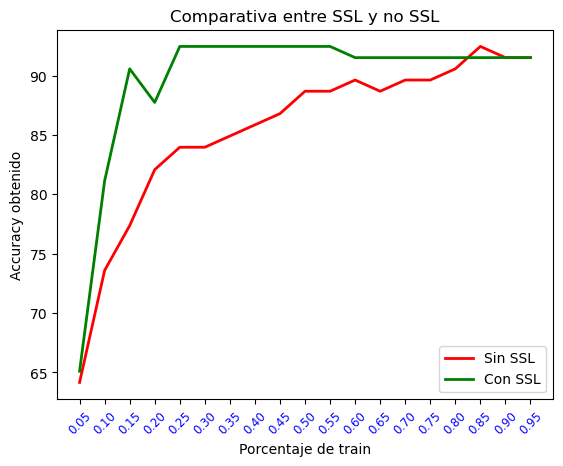

In [27]:
# Llamamos al constructor de SVC (parámetro probability a True, gamma a auto y la semilla a 1)
clf = svm.SVC(probability=True, gamma='auto', random_state=1)
# Asignamos el valor de k (número de ejemplos a etiquetar en cada iteración)
k=1
# Listas para almacenar el rendimiento con y sin aplicar aprendizaje supervisado para cada porcentaje de ejemplos
sinSSL = list([])
conSSL = list([])
# Por cada porcentaje de ejemplos a utilizar como test
for porcentaje in np.arange(0.05,0.96,0.05):
    # Realizamos el particionamiento hold-out usando como entrada los ejemplos de entrenamiento obtenidos en el paso 1
    L, U, L_target, U_target = model_selection.train_test_split(
        X_train, y_train, test_size=porcentaje, random_state=2, stratify=y_train)
    # Entrenamiento del clasificador con los ejemplos del subconjunto L 
    clf.fit(L, L_target)
    # Rendimiento SIN aplicar aprendizaje semi-supervisado
    # Prediccion de las clases de los ejemplos de test iniciales
    pr = clf.predict(X_test)
    # Obtenemos e imprimimos el porcentaje de acierto sin aplicar aprendizaje semi-supervisado
    accuracySinSSL = metrics.accuracy_score(y_test, pr) * 100
    print("Con " + str((1-porcentaje)*100.0) + "% de train sin SSL, resultado en test: " + str(accuracySinSSL))

    # Aplicamos el aprendizaje semi-supervisado
    # Mientras haya ejemplos en U
    while U.shape[0]>0:
        # Entrenamiento del clasificador con los ejemplos del subconjunto L 
        clf.fit(L, L_target) # L crece entonces se reentrena en cada iteración 
        # Prediccion de las probabilidades de los ejemplos del subconjunto U (no etiquetados)
        pr = clf.predict_proba(U)
        # Ordenar las probabilidades por filas
        prAux = np.sort(pr, axis=1)
        # Obtener los índices (clases) al ordenar las probabilidades por filas
        clasesAux = np.argsort(pr, axis=1)
        # Obtener los índices al ordenar la última columna de las probabilidades ordenadas anteriormente
        indices = np.argsort(prAux[:, -1])
        # Seleccionar los k últimos ejemplos de U 
        ejemplos = U[indices[-k:]] # los de mayor confianza 
        # Seleccionar los k últimas clases predichas para los ejemplos de U 
        clases = clasesAux[indices[-k:], -1]
        # Añadir al subconjunto L los ejemplos etiquetados en la iteración
        L = np.vstack((L, ejemplos))
        # Añadir las clases de los ejemplos etiquetados en la iteración (al subconjunto L_target)
        L_target = np.hstack((L_target, clases))
        # Eliminar de U los ejemplos etiquetados en la iteración
        U = np.delete(U, indices[-k:], 0)
        
    # Entrenamiento del clasificador con los ejemplos del subconjunto L
    clf.fit(L, L_target)
    # Prediccion de las clases de los ejemplos de test iniciales
    pr = clf.predict(X_test)
    # Obtenemos e imprimimos el porcentaje de acierto tras aplicar aprendizaje semi-supervisado
    accuracyConSSL = metrics.accuracy_score(y_test, pr) * 100
    print("Con " + str((1-porcentaje)*100.0) + "% de train con SSL, resultado en test: " + str(accuracyConSSL))
    # Añadimos los rendimientos a la lista correspondiente
    sinSSL.append(accuracySinSSL)
    conSSL.append(accuracyConSSL)

# Creamos la figura
plt.figure
# plt.hold(True)
plt.xticks(1-np.arange(0.05,0.96,0.05), size = 'small', color = 'b', rotation = 45)
plt.xlabel("Porcentaje de train")
plt.ylabel("Accuracy obtenido")
plt.title("Comparativa entre SSL y no SSL")
plt.plot(1-np.arange(0.05,0.96,0.05),sinSSL,'r', linewidth = 2, label = 'Sin SSL')
plt.plot(1-np.arange(0.05,0.96,0.05),conSSL,'g', linewidth = 2, label = 'Con SSL')
plt.legend(loc = 4)
plt.show()

In [28]:
Test.assertEquals(list(map(lambda x: round(x, 2), sinSSL)), [91.51,91.51,92.45,90.57,89.62,89.62,88.68,89.62,88.68,88.68,86.79,85.85,84.91,83.96,83.96,82.08,77.36,73.58,64.15], 'Valores de accuracy sin SSL incorrectos')
Test.assertEquals(list(map(lambda x: round(x, 2), conSSL)), [91.51,91.51,91.51,91.51,91.51,91.51,91.51,91.51,92.45,92.45,92.45,92.45,92.45,92.45,92.45,87.74,90.57,81.13,65.09], 'Valores de accuracy con SSL incorrectos')

1 test passed.
1 test passed.


Estudio complementario:
* Probad el método en otros datasets para ver si funciona bien en otro casos. Podéis utilizar los de las prácticas anteriores.
* Probad el método con otros clasificadores para analizar su comportamiento.

Podéis añadir cuantas celdas sean necesarias añadiéndolas con el símbolo + de la cinta de opciones.

Usare los datasets de la práctica 2 donde se hizo estudio estadístico de varios datasets para probar otros clasificadores, usando el código dataset.py actual de esta práctica

In [29]:
import os

# Listamos los ficheros de la carpeta  de la práctica 2
ruta = "datasetsP2/"
ficheros = sorted(f for f in os.listdir(ruta) if f.endswith(".dat"))
print(len(ficheros), "ficheros:", ficheros)

# Compruebo que cada dataset se lee con el dataset.py actual (devuelve tupla) y mostramos sus dimensiones
for f in ficheros:
    try:
        d = ds.lecturaDatos(ruta + f)
        d = d[0] if isinstance(d, tuple) else d
        # np.bincount da el nº de ejemplos por clase (estratificar necesita varios por clase)
        print(f"{f:18s} ejemplos={d.data.shape[0]:5d} atributos={d.data.shape[1]:3d} clases={len(np.unique(d.target))} "
              f"min/max por clase={np.bincount(d.target)[np.bincount(d.target) > 0].min()}/{np.bincount(d.target).max()}")
    except Exception as e:
        print(f"{f:18s} ERROR {type(e).__name__}: {e}")

13 ficheros: ['appendicitis.dat', 'balance.dat', 'bupa.dat', 'ecoli.dat', 'glass.dat', 'haberman.dat', 'iris.dat', 'newthyroid.dat', 'page-blocks.dat', 'pima.dat', 'wine.dat', 'wisconsin.dat', 'yeast.dat']
appendicitis.dat   ejemplos=  106 atributos=  7 clases=2 min/max por clase=21/85
balance.dat        ejemplos=  625 atributos=  4 clases=3 min/max por clase=49/288
bupa.dat           ejemplos=  345 atributos=  6 clases=2 min/max por clase=145/200
ecoli.dat          ejemplos=  336 atributos=  7 clases=8 min/max por clase=2/143
glass.dat          ejemplos=  214 atributos=  9 clases=6 min/max por clase=9/76
haberman.dat       ejemplos=  306 atributos=  3 clases=2 min/max por clase=81/225
iris.dat           ejemplos=  150 atributos=  4 clases=3 min/max por clase=50/50
newthyroid.dat     ejemplos=  215 atributos=  5 clases=3 min/max por clase=30/150
page-blocks.dat    ejemplos= 5472 atributos= 10 clases=5 min/max por clase=28/4913
pima.dat           ejemplos=  768 atributos=  8 clases=2 mi

## Estudio complementario

**Objetivo.** Comprobar si el método self-training funciona igual de bien en otros problemas y con otros clasificadores, y no solo con Ionosphere y la SVM.

**Datasets.** Se utilizan los datasets de la práctica 2 (appendicitis, balance, bupa, glass, haberman, iris, newthyroid, pima, wine y wisconsin), leídos con la misma clase `dataset`. Se descarta el dataset ecoli ya que tiene una clase con solo 2 ejemplos y no permite estratificar con porcentajes pequeños, page-blocks y yeast (demasiado grandes para el coste computacional de self-training con k=1).

**Metodología.** Para cada dataset se repite el experimento del paso 7: partición hold-out 70/30 estratificada, división del train en L (etiquetados) y U (sin etiquetar) con porcentajes del 5% al 95%, y comparación del accuracy en test con y sin aprendizaje semi-supervisado. Los atributos se escalan con `StandardScaler` (ajustado solo con los datos de entrenamiento), porque la SVM con `gamma='auto'` no funciona bien con atributos de escalas muy distintas.

**Criterio.** Se considera que SSL *funciona* en un dataset si la diferencia media de accuracy (con SSL menos sin SSL) es positiva y mejora en más porcentajes de los que empeora.

**Otros clasificadores.** Se repite el estudio con K vecinos más cercanos (KNN), Naive Bayes, árbol de decisión y regresión logística, además de la SVM. Todos disponen de `predict_proba`, necesario para seleccionar los ejemplos con mayor confianza en cada iteración.

In [ ]:
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler

# Self-training (el mismo algoritmo del paso 5) encapsulado para poder reutilizarlo con cualquier clasificador
def selfTraining(clf, L, L_target, U, k):
    while U.shape[0] > 0:
        clf.fit(L, L_target)
        pr = clf.predict_proba(U)                      # el clasificador debe tener predict_proba
        prAux = np.sort(pr, axis=1)
        clasesAux = np.argsort(pr, axis=1)
        indices = np.argsort(prAux[:, -1])             # ordena por confianza (última columna)
        L = np.vstack((L, U[indices[-k:]]))
        # classes_ traduce la columna a la etiqueta real (necesario si faltan clases o no empiezan en 0)
        L_target = np.hstack((L_target, clf.classes_[clasesAux[indices[-k:], -1]]))
        U = np.delete(U, indices[-k:], 0)
    return L, L_target

# Repite los pasos 1 a 7 sobre un dataset y un clasificador; devuelve los accuracy sin y con SSL
def estudio(fichero, clf, k=1, escalar=True):
    d = ds.lecturaDatos(fichero)
    d = d[0] if isinstance(d, tuple) else d            #  el dataset.py actual devuelve (ds, original); el de la práctica 2 solo ds
    # Paso 1: hold-out 70/30 estratificado
    X_train, X_test, y_train, y_test = model_selection.train_test_split(
        d.data, d.target, test_size=0.3, random_state=2, stratify=d.target)
    if escalar:                                        # se ajusta solo con train para no filtrar información del test
        sc = StandardScaler().fit(X_train)
        X_train, X_test = sc.transform(X_train), sc.transform(X_test)
    sinSSL, conSSL = [], []
    for porcentaje in np.arange(0.05, 0.96, 0.05):
        # Paso 3: particionado en L y U
        L, U, L_target, _ = model_selection.train_test_split(
            X_train, y_train, test_size=porcentaje, random_state=2, stratify=y_train)
        # Paso 4: sin SSL ( lo que hice es clonar un clasificador nuevo con los mismos parámetros)
        c = clone(clf).fit(L, L_target)
        sinSSL.append(metrics.accuracy_score(y_test, c.predict(X_test)) * 100)
        # Pasos 5 y 6: con SSL
        L, L_target = selfTraining(clone(clf), L, L_target, U, k)
        c = clone(clf).fit(L, L_target)
        conSSL.append(metrics.accuracy_score(y_test, c.predict(X_test)) * 100)
    return np.array(sinSSL), np.array(conSSL)

# Resume el experimento y decide si SSL "funciona" (dif media > 0 y mejora en más casos de los que empeora)
def resumen(nombre, sinSSL, conSSL):
    dif = conSSL - sinSSL
    mejora, empeora = (dif > 0).sum(), (dif < 0).sum()
    veredicto = "FUNCIONA" if dif.mean() > 0 and mejora > empeora else "no funciona"
    print(f"{nombre:13s} sin={sinSSL.mean():6.2f} con={conSSL.mean():6.2f} dif={dif.mean():+5.2f} "
          f"mejora={mejora:2d} empata={(dif==0).sum():2d} empeora={empeora:2d} -> {veredicto}")
    return dif.mean()

Comparo los cinco clasificadores en haberman, donde SSL no funciona con ninguno, y en pima, donde mejora ligeramente con la SVM y la regresión logística.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# Clasificadores a comparar (todos tienen predict_proba, necesario para self-training)
clasificadores = {
    "SVM": svm.SVC(probability=True, gamma='auto', random_state=1),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "NaiveBayes": GaussianNB(),
    "Arbol": DecisionTreeClassifier(random_state=1),
    "LogReg": LogisticRegression(max_iter=1000, random_state=1),
}
# Datasets de prueba: haberman (SSL no funciona) y pima (mejora marginal con la SVM) 
elegidos = ["haberman", "pima"]

for nombre in elegidos:
    print("== " + nombre)
    for cn, clf in clasificadores.items():
        resumen(cn, *estudio("datasetsP2/" + nombre + ".dat", clf, k=1))

== haberman
SVM           sin= 74.26 con= 74.14 dif=-0.11 mejora= 7 empata= 7 empeora= 5 -> no funciona
KNN           sin= 73.46 con= 73.28 dif=-0.17 mejora= 5 empata= 6 empeora= 8 -> no funciona
NaiveBayes    sin= 75.69 con= 73.46 dif=-2.23 mejora= 3 empata= 5 empeora=11 -> no funciona
Arbol         sin= 66.13 con= 65.96 dif=-0.17 mejora= 9 empata= 1 empeora= 9 -> no funciona
LogReg        sin= 76.72 con= 76.60 dif=-0.11 mejora= 5 empata= 7 empeora= 7 -> no funciona
== pima
SVM           sin= 75.51 con= 75.67 dif=+0.16 mejora=10 empata= 1 empeora= 8 -> FUNCIONA
KNN           sin= 75.32 con= 71.88 dif=-3.44 mejora= 2 empata= 0 empeora=17 -> no funciona
NaiveBayes    sin= 73.59 con= 70.90 dif=-2.69 mejora= 1 empata= 0 empeora=18 -> no funciona
Arbol         sin= 69.54 con= 69.61 dif=+0.07 mejora= 8 empata= 0 empeora=11 -> no funciona
LogReg        sin= 75.35 con= 76.03 dif=+0.68 mejora=13 empata= 2 empeora= 4 -> FUNCIONA


### Self-training en Ionosphere con distintos clasificadores

En este apartado compruebo si el buen resultado de self-training en Ionosphere depende del clasificador o si se mantiene con otros. Para ello defino la función `estudioXY`, que repite el experimento del paso 7 partiendo de los datos ya particionados en el paso 1 (`X_train`, `X_test`, `y_train` e `y_test`), de modo que el conjunto de test es siempre el mismo y los resultados son comparables.

Para cada porcentaje de ejemplos no etiquetados, entre el 5% y el 95%, divido el entrenamiento en L (con etiquetas) y U (sin etiquetas) con estratificación y semilla 2. Después entreno un clasificador nuevo solo con L, que es el resultado sin aprendizaje semi-supervisado. A continuación aplico self-training con otro clasificador nuevo, que añade a L, de uno en uno (k=1), los ejemplos de U en los que más confía, y entreno un último clasificador con el L ya ampliado, que es el resultado con aprendizaje semi-supervisado. Uso `clone` para que cada entrenamiento parta de un clasificador sin estado previo y no se arrastre información entre iteraciones.

Aplico la función a los cinco clasificadores (SVM, KNN, Naive Bayes, árbol de decisión y regresión logística), sin escalar los atributos, igual que en el resto de la práctica con Ionosphere. Para cada uno muestro el accuracy medio sin y con SSL, la diferencia media y en cuántos porcentajes mejora, empata o empeora.

In [35]:
# Igual que estudio(), pero partiendo de los datos ya particionados (paso 1) en lugar de leer un fichero
def estudioXY(X_train, X_test, y_train, y_test, clf, k=1):
    sinSSL, conSSL = [], []
    for porcentaje in np.arange(0.05, 0.96, 0.05):
        L, U, L_target, _ = model_selection.train_test_split(
            X_train, y_train, test_size=porcentaje, random_state=2, stratify=y_train)
        c = clone(clf).fit(L, L_target)                          # sin SSL
        sinSSL.append(metrics.accuracy_score(y_test, c.predict(X_test)) * 100)
        L, L_target = selfTraining(clone(clf), L, L_target, U, k)  # con SSL
        c = clone(clf).fit(L, L_target)
        conSSL.append(metrics.accuracy_score(y_test, c.predict(X_test)) * 100)
    return np.array(sinSSL), np.array(conSSL)

# Ionosphere con todos los clasificadores definidos antes (sin escalar, como en la práctica)
res_ion = {}
for cn, clf in clasificadores.items():
    res_ion[cn] = estudioXY(X_train, X_test, y_train, y_test, clf, k=1)
    resumen(cn, *res_ion[cn])

SVM           sin= 85.45 con= 89.67 dif=+4.22 mejora=16 empata= 2 empeora= 1 -> FUNCIONA
KNN           sin= 75.42 con= 69.71 dif=-5.71 mejora= 5 empata= 0 empeora=14 -> no funciona
NaiveBayes    sin= 83.66 con= 79.10 dif=-4.57 mejora= 0 empata= 1 empeora=18 -> no funciona
Arbol         sin= 81.38 con= 80.88 dif=-0.50 mejora= 4 empata= 8 empeora= 7 -> no funciona
LogReg        sin= 81.63 con= 79.74 dif=-1.89 mejora= 6 empata= 4 empeora= 9 -> no funciona


### Comparativa gráfica por clasificador

Represento los resultados anteriores con una gráfica por clasificador, con la misma estructura que la del paso 7. En el eje horizontal está el porcentaje de datos de entrenamiento etiquetados (L) y en el vertical el accuracy obtenido en test. La línea roja es el resultado sin aprendizaje semi-supervisado y la verde el resultado con self-training.

Con estas gráficas puedo ver, para cada clasificador, en qué porcentajes ayuda el aprendizaje semi-supervisado (la línea verde queda por encima de la roja), en cuáles no aporta nada (las líneas coinciden) y en cuáles empeora el resultado (la verde queda por debajo). Como el sexto cuadro de la cuadrícula queda vacío, porque hay cinco clasificadores, lo oculto.

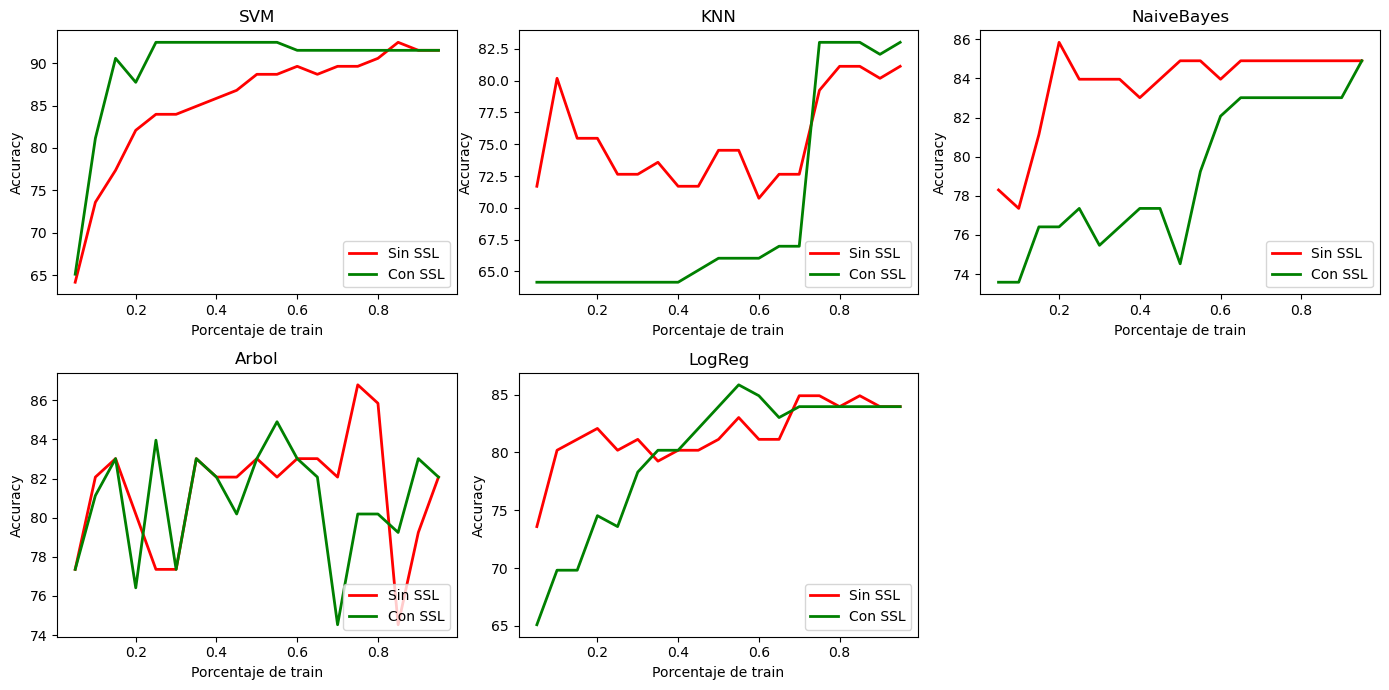

In [36]:
# Una gráfica por clasificador con las curvas sin SSL (rojo) y con SSL (verde), como en el paso 7
x = 1 - np.arange(0.05, 0.96, 0.05)                              # porcentaje de train (L)
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for eje, (cn, (a, b)) in zip(ejes.ravel(), res_ion.items()):
    eje.plot(x, a, 'r', linewidth=2, label='Sin SSL')
    eje.plot(x, b, 'g', linewidth=2, label='Con SSL')
    eje.set_title(cn); eje.set_xlabel("Porcentaje de train"); eje.set_ylabel("Accuracy"); eje.legend(loc=4)
ejes.ravel()[-1].axis('off')                                     # sobra el sexto cuadro (hay 5 clasificadores)
plt.tight_layout(); plt.show()

### Self-training con la SVM en otros datasets

Para comprobar si self-training funciona también en otros problemas, repito el experimento del paso 7 con los datasets de la práctica 2 (appendicitis, balance, bupa, glass, haberman, iris, newthyroid, pima, wine y wisconsin). Mantengo el mismo clasificador que en el resto de la práctica: una SVM con `probability=True`, `gamma='auto'` y semilla 1.

Para cada dataset, la función `estudio` lee el fichero con la clase `dataset`, hace el hold-out 70/30 estratificado, escala los atributos con `StandardScaler` (ajustado solo con el entrenamiento) y calcula el accuracy con y sin self-training para los porcentajes de L entre el 5% y el 95%. Con `k=1`, añado a L los ejemplos de U de uno en uno. Guardo los resultados en el diccionario `resultados` y, con la función `resumen`, muestro el accuracy medio sin y con SSL, la diferencia y en cuántos porcentajes mejora, empata o empeora. Considero que SSL funciona si la diferencia media es positiva y mejora en más porcentajes de los que empeora. Dejo fuera ecoli, page-blocks y yeast: ecoli tiene una clase con solo 2 ejemplos y no permite estratificar con porcentajes pequeños, y los otros dos son demasiado grandes para el coste de reentrenar la SVM en cada iteración.

In [37]:
# Clasificador de la práctica (SVM con probability=True, gamma auto y semilla 1)
svc = svm.SVC(probability=True, gamma='auto', random_state=1)
# Datasets a probar (se excluyen ecoli, page-blocks y yeast por los motivos explicados antes)
datasets = ["appendicitis", "balance", "bupa", "glass", "haberman", "iris", "newthyroid", "pima", "wine", "wisconsin"]
resultados = {}
for nombre in datasets:
    # estudio() lee el dataset, escala los atributos y repite el experimento del paso 7 para cada porcentaje
    resultados[nombre] = estudio("datasetsP2/" + nombre + ".dat", svc, k=1)
    resumen(nombre, *resultados[nombre])

appendicitis  sin= 89.97 con= 89.64 dif=-0.33 mejora= 6 empata= 9 empeora= 4 -> no funciona
balance       sin= 88.19 con= 85.83 dif=-2.35 mejora= 1 empata= 4 empeora=14 -> no funciona
bupa          sin= 63.66 con= 62.50 dif=-1.16 mejora= 6 empata= 2 empeora=11 -> no funciona
glass         sin= 60.73 con= 58.14 dif=-2.59 mejora= 5 empata= 2 empeora=12 -> no funciona
haberman      sin= 74.26 con= 74.14 dif=-0.11 mejora= 7 empata= 7 empeora= 5 -> no funciona
iris          sin= 95.44 con= 87.95 dif=-7.49 mejora= 0 empata= 0 empeora=19 -> no funciona
newthyroid    sin= 94.57 con= 93.68 dif=-0.89 mejora= 4 empata= 8 empeora= 7 -> no funciona
pima          sin= 75.51 con= 75.67 dif=+0.16 mejora=10 empata= 1 empeora= 8 -> FUNCIONA
wine          sin= 98.83 con= 95.32 dif=-3.51 mejora= 0 empata=14 empeora= 5 -> no funciona
wisconsin     sin= 97.10 con= 96.97 dif=-0.13 mejora= 2 empata=10 empeora= 7 -> no funciona


## Conclusiones del estudio complementario

**¿Qué he hecho?** He aplicado self-training en inductive learning sobre Ionosphere (pasos 1 a 7) y he ampliado el estudio en dos direcciones: probando el método en otros 10 datasets con la SVM y probando otros cuatro clasificadores (KNN, Naive Bayes, árbol de decisión y regresión logística) en Ionosphere, pima y haberman.

**Resultado en Ionosphere (SVM).** Self-training mejora el accuracy de forma clara cuando hay pocos datos etiquetados. Con el 30% de etiquetas pasa de 83.96% a 92.45%, y llega a superar el 89.62% del aprendizaje supervisado con todas las etiquetas. En el estudio de todos los porcentajes la mejora media es de +4.22 puntos, y mejora en 16 de los 19 casos. La ventaja desaparece cuando hay muchas etiquetas (más del 80% de train), porque queda poca información que aportar desde U, y también con muy pocas (5%), porque las primeras predicciones son poco fiables y los errores se propagan.

**Otros datasets (SVM).** Self-training no mejora de forma general. De los 10 datasets probados, solo pima sale con diferencia positiva (+0.16), y es marginal, porque equivale a menos de un ejemplo de test. En el resto el resultado es neutro o peor, con los casos más negativos en iris (-7.49), wine (-3.51), glass (-2.59) y balance (-2.35). Mi interpretación, que no he contrastado con pruebas específicas, es que influyen tres factores: un acierto inicial ya muy alto (wine, wisconsin, iris), que deja poco margen de mejora; clases muy solapadas (bupa, haberman, pima), donde las predicciones iniciales son poco fiables; y pocos ejemplos con varias clases (glass, iris, wine), donde algunas clases quedan casi sin representar en L.

**Otros clasificadores.** El resultado depende mucho del clasificador. En Ionosphere solo la SVM se beneficia (+4.22), mientras que KNN (-5.71), Naive Bayes (-4.57), regresión logística (-1.89) y árbol (-0.50) empeoran de media. En pima, la regresión logística es la que más mejora (+0.68) y KNN y Naive Bayes empeoran casi siempre. En KNN con SSL se observa que el accuracy se queda en el valor de la clase mayoritaria con pocas etiquetas, es decir, el clasificador acaba prediciendo siempre la misma clase. Interpreto que self-training necesita que el clasificador dé probabilidades fiables: KNN con pocos vecinos produce probabilidades con muchos empates, Naive Bayes suele ser demasiado seguro de sí mismo y el árbol de decisión da probabilidades casi siempre de 0 o 1, de modo que la confianza no permite elegir bien qué ejemplos añadir.

**Conclusión final.** Self-training puede mejorar de forma notable el rendimiento cuando hay pocos datos etiquetados, como ocurre en Ionosphere con la SVM, pero no es una mejora garantizada. Su resultado depende del clasificador (que sus probabilidades sean fiables), del dataset (acierto inicial, separabilidad de las clases y número de ejemplos por clase) y de la cantidad de datos etiquetados disponibles. Cuando los errores de las primeras etiquetas asignadas se propagan, el método puede empeorar el resultado respecto a no usar datos sin etiquetar.

